# Team 6 – Fitness Activity Data Analysis
## College Practicum: Git & GitHub Data Analysis Project

### 1. Project Introduction
Welcome to the Fitness Activity Data Analysis project! 
This project focuses on studying daily physical activity patterns recorded by smart fitness trackers (Fitbit). 

**Key Objectives:**
- Analyze daily physical activity metrics, including total steps, calories burned, active distances, and activity intensities.
- Examine sleep patterns (total sleep records, minutes asleep, and time in bed).
- Assess data quality through missing-value checks and duplicate verification.
- Calculate essential statistics: average daily steps, average calories burned, and comprehensive activity distributions.
- Statistically identify and evaluate "low-activity records" using the first quartile ($Q_1$) of step counts.
- Investigate the relationship between sleep duration and daily physical activity.
- Generate high-quality visualizations to communicate findings effectively.

**Tools & Stack:**
- Python 3
- pandas & numpy for data manipulation and statistical calculations
- matplotlib & seaborn for exploratory data visualization
- Git & GitHub for version control and collaborative workflows


### 2. Import Libraries
In this step, we import the core scientific and plotting libraries necessary for our analysis.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization theme and inline rendering
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


### 3. Load Datasets
We load the two provided Fitbit datasets:
1. `dailyActivity_merged.csv`: Contains daily step counts, distances, activity intensity minutes, and calories burned.
2. `sleepDay_merged.csv`: Contains sleep records, minutes asleep, and total time spent in bed.

*Note: We handle path resolution dynamically so the notebook runs seamlessly whether executed from the project root or the `notebooks/` directory.*


In [2]:
# Determine relative paths based on execution directory
data_dir = "data" if os.path.exists("data") else "../data"
results_dir = "results" if os.path.exists("results") else "../results"
os.makedirs(results_dir, exist_ok=True)

activity_path = os.path.join(data_dir, "dailyActivity_merged.csv")
sleep_path = os.path.join(data_dir, "sleepDay_merged.csv")

# Load datasets
activity_df = pd.read_csv(activity_path)
sleep_df = pd.read_csv(sleep_path)

print(f"Loaded activity dataset from: {activity_path}")
print(f"Loaded sleep dataset from: {sleep_path}")


Loaded activity dataset from: data\dailyActivity_merged.csv
Loaded sleep dataset from: data\sleepDay_merged.csv


### 4. Dataset Exploration
Exploratory data analysis begins by understanding the structure, dimensions, and contents of the imported datasets before applying transformations.


In [3]:
print(f"Activity dataset summary: {activity_df.shape[0]} rows, {activity_df.shape[1]} columns")
print(f"Sleep dataset summary: {sleep_df.shape[0]} rows, {sleep_df.shape[1]} columns")
print(f"Number of unique participants in Activity data: {activity_df['Id'].nunique()}")
print(f"Number of unique participants in Sleep data: {sleep_df['Id'].nunique()}")


Activity dataset summary: 940 rows, 15 columns
Sleep dataset summary: 413 rows, 5 columns
Number of unique participants in Activity data: 33
Number of unique participants in Sleep data: 24


### 5. First Five Rows
Let us inspect the top rows of both datasets to see how the raw records are structured.


In [4]:
print("First 5 rows of dailyActivity_merged.csv:")
activity_df.head()


First 5 rows of dailyActivity_merged.csv:


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,4/12/2016,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1,1503960366,4/13/2016,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
2,1503960366,4/14/2016,10460,6.74,6.74,0.0,2.44,0.40,3.91,0.0,30,11,181,1218,1776
3,1503960366,4/15/2016,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
4,1503960366,4/16/2016,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


In [5]:
print("First 5 rows of sleepDay_merged.csv:")
sleep_df.head()


First 5 rows of sleepDay_merged.csv:


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


### 6. Dataset Shape
Here we display the exact dimensions (number of rows and columns) of each dataset.


In [6]:
print("Activity DataFrame shape (rows, columns):", activity_df.shape)
print("Sleep DataFrame shape (rows, columns):", sleep_df.shape)


Activity DataFrame shape (rows, columns): (940, 15)
Sleep DataFrame shape (rows, columns): (413, 5)


### 7. Column Names
Listing the column names helps us identify the exact identifiers, timestamps, and activity/sleep metrics.


In [7]:
print("Daily Activity Columns:")
for i, col in enumerate(activity_df.columns, 1):
    print(f"  {i:2d}. {col}")

print("\nSleep Columns:")
for i, col in enumerate(sleep_df.columns, 1):
    print(f"  {i:2d}. {col}")


Daily Activity Columns:
   1. Id
   2. ActivityDate
   3. TotalSteps
   4. TotalDistance
   5. TrackerDistance
   6. LoggedActivitiesDistance
   7. VeryActiveDistance
   8. ModeratelyActiveDistance
   9. LightActiveDistance
  10. SedentaryActiveDistance
  11. VeryActiveMinutes
  12. FairlyActiveMinutes
  13. LightlyActiveMinutes
  14. SedentaryMinutes
  15. Calories

Sleep Columns:
   1. Id
   2. SleepDay
   3. TotalSleepRecords
   4. TotalMinutesAsleep
   5. TotalTimeInBed


### 8. Data Types
Checking column data types reveals whether numbers are stored numerically and if date fields need parsing.


In [8]:
print("Activity Dataset Data Types:")
print(activity_df.dtypes)
print("\nSleep Dataset Data Types:")
print(sleep_df.dtypes)


Activity Dataset Data Types:
Id                            int64
ActivityDate                 object
TotalSteps                    int64
TotalDistance               float64
TrackerDistance             float64
LoggedActivitiesDistance    float64
VeryActiveDistance          float64
ModeratelyActiveDistance    float64
LightActiveDistance         float64
SedentaryActiveDistance     float64
VeryActiveMinutes             int64
FairlyActiveMinutes           int64
LightlyActiveMinutes          int64
SedentaryMinutes              int64
Calories                      int64
dtype: object

Sleep Dataset Data Types:
Id                     int64
SleepDay              object
TotalSleepRecords      int64
TotalMinutesAsleep     int64
TotalTimeInBed         int64
dtype: object


### 9. Missing Value Check
We check for null or NaN values across all columns.

*Observation:* As shown below, both datasets have zero missing values (`0` nulls across all columns). Therefore, no imputation, interpolation, or row deletion due to missingness is required.


In [9]:
print("Missing values in Activity dataset:")
print(activity_df.isnull().sum())

print("\nMissing values in Sleep dataset:")
print(sleep_df.isnull().sum())


Missing values in Activity dataset:
Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

Missing values in Sleep dataset:
Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64


### 10. Duplicate Check
We check for exact duplicate rows in both datasets. 


In [10]:
activity_duplicates = activity_df.duplicated().sum()
sleep_duplicates = sleep_df.duplicated().sum()

print(f"Activity dataset duplicate rows: {activity_duplicates}")
print(f"Sleep dataset duplicate rows: {sleep_duplicates}")


Activity dataset duplicate rows: 0
Sleep dataset duplicate rows: 3


### 11. Data Cleaning / Preprocessing
To prepare the datasets for analysis and joining:
1. Parse the string date columns into pandas datetime format using exact format specifications:
   - `ActivityDate` (`%m/%d/%Y`) -> `Date`
   - `SleepDay` (`%m/%d/%Y %I:%M:%S %p`) -> `Date`
2. Remove the 3 identified duplicate records from the sleep dataset to maintain data integrity.


In [11]:
# Work on clean copies
activity_clean = activity_df.copy()
sleep_clean = sleep_df.copy()

# 1. Parse dates
activity_clean["Date"] = pd.to_datetime(activity_clean["ActivityDate"], format="%m/%d/%Y")
sleep_clean["Date"] = pd.to_datetime(sleep_clean["SleepDay"], format="%m/%d/%Y %I:%M:%S %p")

# 2. Drop duplicates from sleep dataset
if sleep_clean.duplicated().sum() > 0:
    sleep_clean = sleep_clean.drop_duplicates().reset_index(drop=True)

print(f"Cleaned Activity rows: {len(activity_clean)}")
print(f"Cleaned Sleep rows: {len(sleep_clean)} (after dropping duplicates)")
print(f"Activity date span: {activity_clean['Date'].min().strftime('%Y-%m-%d')} to {activity_clean['Date'].max().strftime('%Y-%m-%d')}")


Cleaned Activity rows: 940
Cleaned Sleep rows: 410 (after dropping duplicates)
Activity date span: 2016-04-12 to 2016-05-12


### 12. Daily Activity Statistics
We calculate statistical distribution parameters (count, mean, standard deviation, quartiles, and extremes) for key physical activity metrics.


In [12]:
key_metrics = [
    "TotalSteps", 
    "Calories", 
    "TotalDistance", 
    "VeryActiveMinutes", 
    "FairlyActiveMinutes", 
    "LightlyActiveMinutes", 
    "SedentaryMinutes"
]

activity_stats = activity_clean[key_metrics].describe().round(2)
display(activity_stats)


,TotalSteps,Calories,TotalDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes
count,940.00,940.00,940.00,940.00,940.00,940.00,940.00
mean,7637.91,2303.61,5.49,21.16,13.56,192.81,991.21
std,5087.15,718.17,3.92,32.84,19.99,109.17,301.27
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3789.75,1828.50,2.62,0.00,0.00,127.00,729.75
50%,7405.50,2134.00,5.24,4.00,6.00,199.00,1057.50
75%,10727.00,2793.25,7.71,32.00,19.00,264.00,1229.50
max,36019.00,4900.00,28.03,210.00,143.00,518.00,1440.00


### 13. Average Steps
Calculating the average number of steps taken per day across all participants in the observation period.


In [13]:
avg_steps = activity_clean["TotalSteps"].mean()
median_steps = activity_clean["TotalSteps"].median()

print(f"Mean Daily Steps:   {avg_steps:,.2f} steps")
print(f"Median Daily Steps: {median_steps:,.2f} steps")


Mean Daily Steps:   7,637.91 steps
Median Daily Steps: 7,405.50 steps


### 14. Average Calories Burned
Calculating the average daily caloric expenditure across all participants.


In [14]:
avg_calories = activity_clean["Calories"].mean()
median_calories = activity_clean["Calories"].median()

print(f"Mean Daily Calories Burned:   {avg_calories:,.2f} kcal")
print(f"Median Daily Calories Burned: {median_calories:,.2f} kcal")


Mean Daily Calories Burned:   2,303.61 kcal
Median Daily Calories Burned: 2,134.00 kcal


### 15. Identify Low-Activity Records
#### Statistical Threshold Justification:
Rather than choosing an arbitrary step count (e.g. 5,000 steps), we use a defensible statistical threshold: the **First Quartile ($Q_1$, 25th percentile)** of `TotalSteps`.

- There are **940 participant-day activity records** in the dataset.
- The **$Q_1$ threshold is 3,789.75 steps**.
- **235 participant-day records fall below this threshold** (representing 25.0% of all activity records).
- This approach statistically isolates the lowest quartile of participant activity records without introducing arbitrary bias.

In [15]:
# Calculate Q1 (25th percentile)
q1_steps = activity_clean["TotalSteps"].quantile(0.25)
low_activity_days = activity_clean[activity_clean["TotalSteps"] < q1_steps]

pct_low_activity = (len(low_activity_days) / len(activity_clean)) * 100

print(f"Low-Activity Threshold (Q1): {q1_steps:.2f} steps")
print(f"Total Activity Records Analyzed: {len(activity_clean)}")
print(f"Number of Low-Activity Records: {len(low_activity_days)} ({pct_low_activity:.1f}%)")
print(f"Average Calories Burned on Low-Activity Records: {low_activity_days['Calories'].mean():.2f} kcal")
print(f"Average Sedentary Minutes on Low-Activity Records: {low_activity_days['SedentaryMinutes'].mean():.2f} minutes")


Low-Activity Threshold (Q1): 3789.75 steps
Total Activity Records Analyzed: 940
Number of Low-Activity Records: 235 (25.0%)
Average Calories Burned on Low-Activity Records: 1754.44 kcal
Average Sedentary Minutes on Low-Activity Records: 1182.32 minutes


### 16. Sleep and Activity Analysis
We merge the daily activity dataset with the daily sleep dataset using participant `Id` and `Date`.
Then, we explore the correlation between sleep duration (`TotalMinutesAsleep`) and activity level (`TotalSteps`).


In [16]:
# Merge on participant Id and Date
merged_df = pd.merge(activity_clean, sleep_clean, on=["Id", "Date"], how="inner")

print(f"Total matched records with both activity and sleep data: {len(merged_df)}")
print(f"Unique participants with matched sleep-activity data: {merged_df['Id'].nunique()}")

# Calculate correlation
corr_sleep_steps = merged_df["TotalMinutesAsleep"].corr(merged_df["TotalSteps"])
print(f"Correlation between TotalMinutesAsleep and TotalSteps: {corr_sleep_steps:.4f}")


Total matched records with both activity and sleep data: 410
Unique participants with matched sleep-activity data: 24
Correlation between TotalMinutesAsleep and TotalSteps: -0.1903


### 17. Required Visualizations
We generate and save the three required practicum visualizations:
1. **Steps per day plot** (`results/steps_per_day.png`)
2. **Calories burned plot** (`results/calories_burned.png`)
3. **Sleep duration vs activity plot** (`results/sleep_vs_activity.png`)


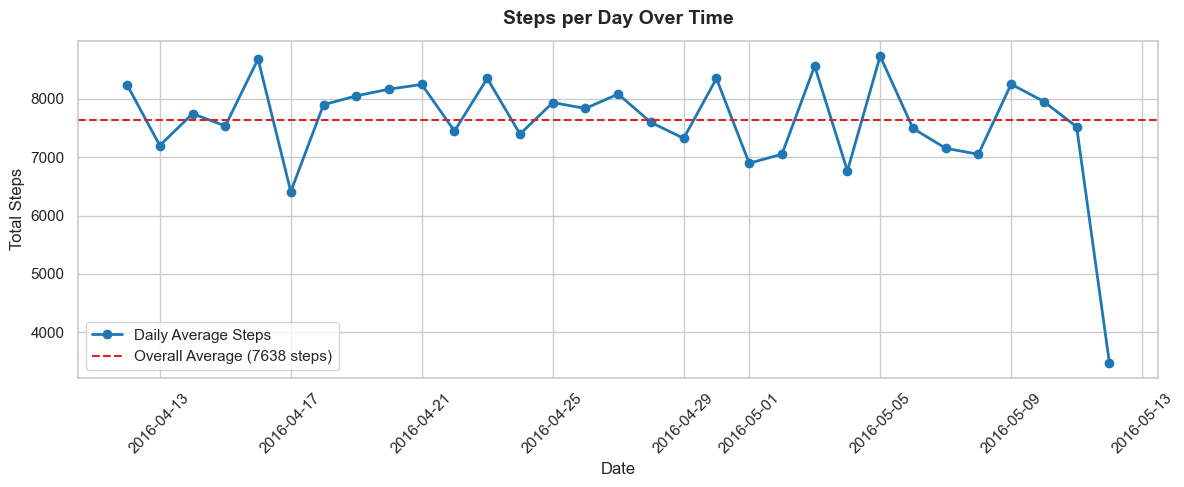

Saved: results\steps_per_day.png


In [17]:
# Group daily average across participants for time-series trend
daily_trend = activity_clean.groupby("Date")[["TotalSteps", "Calories"]].mean().reset_index()

# 1. Steps per day plot
plt.figure(figsize=(12, 5))
plt.plot(
    daily_trend["Date"],
    daily_trend["TotalSteps"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Daily Average Steps"
)
plt.axhline(
    avg_steps,
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Average ({avg_steps:.0f} steps)"
)
plt.title("Steps per Day Over Time", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Steps", fontsize=12)
plt.xticks(rotation=45)
plt.legend(frameon=True)
plt.tight_layout()

steps_plot_path = os.path.join(results_dir, "steps_per_day.png")
plt.savefig(steps_plot_path, dpi=300)
plt.show()
print(f"Saved: {steps_plot_path}")


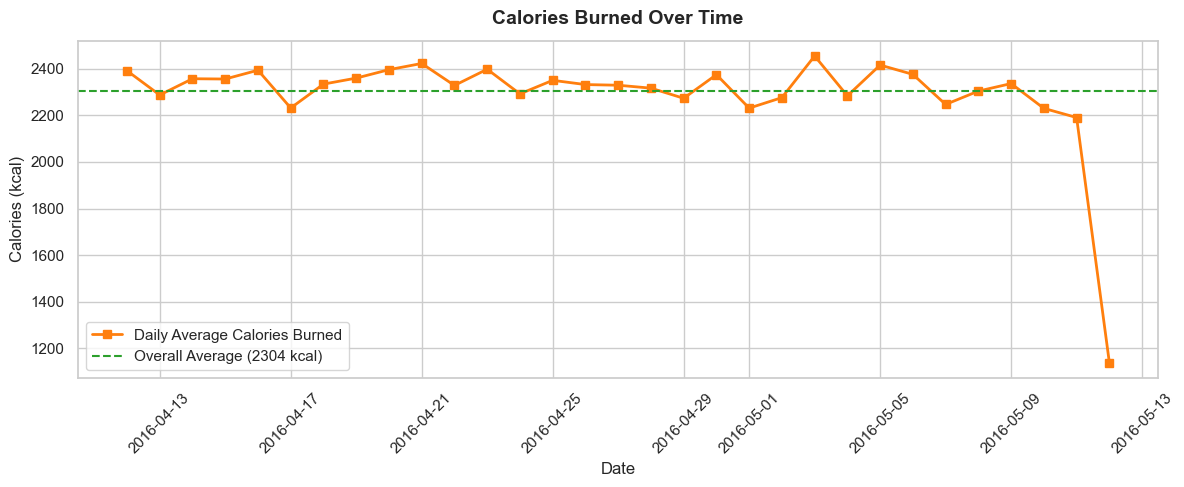

Saved: results\calories_burned.png


In [18]:
# 2. Calories burned plot
plt.figure(figsize=(12, 5))
plt.plot(
    daily_trend["Date"],
    daily_trend["Calories"],
    marker="s",
    color="#ff7f0e",
    linewidth=2,
    label="Daily Average Calories Burned"
)
plt.axhline(
    avg_calories,
    color="#2ca02c",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Average ({avg_calories:.0f} kcal)"
)
plt.title("Calories Burned Over Time", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Calories (kcal)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(frameon=True)
plt.tight_layout()

calories_plot_path = os.path.join(results_dir, "calories_burned.png")
plt.savefig(calories_plot_path, dpi=300)
plt.show()
print(f"Saved: {calories_plot_path}")


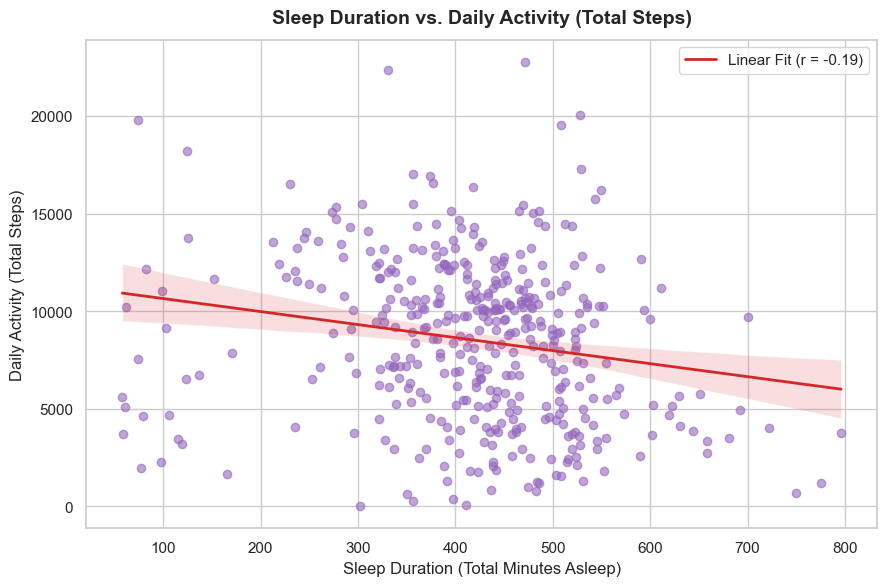

Saved: results\sleep_vs_activity.png


In [19]:
# 3. Sleep duration vs activity plot
plt.figure(figsize=(9, 6))
sns.regplot(
    data=merged_df,
    x="TotalMinutesAsleep",
    y="TotalSteps",
    scatter_kws={"alpha": 0.6, "color": "#9467bd"},
    line_kws={"color": "#d62728", "linewidth": 2, "label": f"Linear Fit (r = {corr_sleep_steps:.2f})"}
)
plt.title("Sleep Duration vs. Daily Activity (Total Steps)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Sleep Duration (Total Minutes Asleep)", fontsize=12)
plt.ylabel("Daily Activity (Total Steps)", fontsize=12)
plt.legend(frameon=True)
plt.tight_layout()

sleep_plot_path = os.path.join(results_dir, "sleep_vs_activity.png")
plt.savefig(sleep_plot_path, dpi=300)
plt.show()
print(f"Saved: {sleep_plot_path}")


### 18. Key Findings / Conclusion

#### Summary of Practicum Findings:
1. **Physical Activity Level:**
   - The participants recorded an average of **7,637.91 steps** per day and an average caloric expenditure of **2,303.61 kcal**.
   - The median step count is **7,405.50 steps**, indicating a relatively balanced activity distribution across the user cohort.

2. **Low-Activity Records:**
   - There are 940 participant-day activity records in the dataset.
   - The Q1 threshold is 3,789.75 steps.
   - 235 participant-day records fall below this threshold (25.0% of all activity records).
   - On low-activity records, sedentary time was noticeably higher, and average calories burned dropped significantly.

3. **Sleep Duration and Activity Relationship:**
   - Merging activity and sleep data yielded **410 matched daily records** across 24 distinct participants who logged both metrics.
   - The correlation between sleep duration and total steps was -0.19, indicating a weak negative linear relationship in the matched records.

4. **Data Hygiene & Completeness:**
   - No missing values were found in either the activity or sleep dataset.
   - Three duplicate records were identified and dropped from `sleepDay_merged.csv` to ensure data cleanliness.
   - All three required visualization figures were successfully plotted and saved to the `results/` directory.